# Heat-Risk Screening — Deliverable 1

**Course:** Computational Data Analysis with Python (CDAP), TUM  
**Track:** Track 1 — Heat-risk screening  
**Group:** Jonas Juchelka & Kriti Shrestha  
**Date:** May 2026

**Dataset:** FAIRUrbTemp curated subset (Amini et al., 2026, *Scientific Data*) — `archive/`

---

**Notebook structure (mapped to D1 rubric):**

| Section | Rubric category | Weight |
|---|---|---:|
| 1. Problem framing | Problem formulation | 30% |
| 2. Data loading & first inspection | Data understanding | (part of 30%) |
| 3. Data quality audit | Data understanding | 30% |
| 4. Exploratory data analysis | EDA | 30% |
| 5. Summary & open questions | Communication | 10% |

Each EDA figure is tagged with its **purpose** (Describe / Diagnose / Discover / Decide), per Session 4 of the course.

## 0. Setup & Imports

In [22]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot style — viridis-family palettes, perceptually uniform; no rainbow (S04 cheatsheet).
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# We deliberately keep warnings ON during EDA — pandas warnings are often the first signal of a data issue.
# warnings.filterwarnings('ignore')

print('Libraries loaded.')
print(f'pandas {pd.__version__}, numpy {np.__version__}, seaborn {sns.__version__}')

Libraries loaded.
pandas 2.3.3, numpy 2.4.4, seaborn 0.13.2


---

## 1. Problem framing

### 1.1 Research question

> **Among the stations in the FAIRUrbTemp curated subset (2019–2022 summers), which locations experience the highest heat exposure, and how stable is that ranking under different reasonable choices of metric, threshold, and time window?**

The question is intentionally narrow. We are not asking *why* some stations are hotter, nor whether they will be hotter in the future. We ask, descriptively, **where the data we have points to the highest exposure**, and how confident we should be in that pointing.

### 1.2 Motivation

European cities are warming faster than the global average, and street-level heat exposure is increasingly recognised as a public health risk — particularly during summer. Heat is not uniform within a city: a sensor on a tree-lined residential street and a sensor on an asphalt square a kilometre away can record very different temperatures during the same heatwave. For a planner deciding where to install shade structures, plant trees, or open cooling centres, a city-average temperature is too coarse to act on. What they need is a **station- or neighbourhood-level ranking of heat risk**, plus an honest sense of how much that ranking depends on the choices made in the analysis.

FAIRUrbTemp provides street-level (2–4 m) air-temperature measurements across 12 European cities (9 with hourly data in our subset), quality-controlled through a 7-step pipeline. This is a strong empirical basis for a heat-risk screening, *within the bounds of its sampling frame*.

### 1.3 Target & intended use

| Element | Definition |
|---|---|
| **Variable measured** | Hourly air temperature `ta` (°C) |
| **Target** | Per-station heat-risk score derived from `ta`. Two candidate definitions, both standard in the heat-exposure literature: **(A) threshold exceedance** — hours per summer with `ta ≥ T °C`; **(B) distributional** — 95th percentile of summer hourly `ta` per station. We report both in D1 and compare. |
| **Unit of analysis** | Weather station |
| **Intended use** | **Screening tool** — produce a ranked list of stations to prioritize for further site investigation. Not a forecast. Not a causal attribution. |
| **Decision frame** | *"Given a fixed budget for heat-mitigation interventions across these European cities, which 10–20 locations should be investigated first, and how robust is that selection?"* |
| **Success criteria** | (1) Heat-risk metric defined precisely enough to re-compute. (2) Honest data-quality audit. (3) Descriptive picture (distributions, cycles, within-city spread) that motivates the metric. (4) Limitations named explicitly. *A quantitative final ranking is a D2 deliverable, not a D1 one.* |

### 1.4 Scope

- **Cities (hourly data, 9):** Amsterdam, Basel, Berlin, Bern, Biel, Birmingham, Freiburg, Novi Sad, Zurich. (Three further cities — Ghent, Rennes, Turku — have metadata only.)
- **Stations:** ~712 across the 9 hourly cities (densest: Zurich 276, Basel 215; sparsest: Berlin 11).
- **Default study window:** **summer 2019–2022 (June–August)** — the only window with reasonable cross-city overlap. Adjusted/relaxed where motivated.

### 1.5 Assumptions and known limitations

- **Sampling frame is opportunistic, not representative.** Cities are those for which COST Action FAIRNESS partners contributed quality-controlled data; biased toward central/Western Europe. Conclusions cannot be generalised to "European cities" as a whole.
- **Within-city station placement is not random.** Sensors were installed for research purposes (e.g., urban heat-island studies). Some neighbourhoods are densely instrumented; others have none. Absence of a high-risk station in an area is not evidence of low risk.
- **Time coverage is uneven across cities.** Cross-city comparisons must hold the time window constant.
- **Missing-data rates are extreme and variable across cities** (preliminary check: from ~0.2% in Bern to ~54% in Birmingham in sample files; verified in Section 3.2). Rankings must explicitly account for completeness.
- **Only one variable is measured.** No humidity, wind, solar radiation, or land-cover features. "Heat risk" here is exposure to high air temperature only — not the full thermal-comfort or health-risk picture.
- **No causal claims.** Differences between stations may reflect microclimate, sensor placement, sensor model, or measurement artefacts. We can describe; we cannot attribute.

---

## 2. Data loading & first inspection

FAIRUrbTemp is distributed in **SEF (Station Exchange Format)** — one TSV per station, with a 12-line metadata header followed by a tabular `Year, Month, Day, Hour, Minute, Period, Value, Meta` block. Missing values are the literal string `NA`. Station metadata (lat, lon, sensor height) lives in separate per-city TSVs.

We:
1. Define a parser for one SEF file.
2. Loop over all ~712 hourly station files across 9 city folders → tidy long-format DataFrame `hourly`.
3. Cache the result to a local parquet (~ tens of MB) so re-running the notebook is fast.
4. Load station / network / measurement metadata.

> The dataset is expected at `archive/` (relative to this notebook). The `cache/` folder is git-ignored; the parquet is regenerated from `archive/` if missing.

### 2.1 SEF parser

In [23]:
ARCHIVE = Path('../archive')
HOURLY_DIR = ARCHIVE / 'data' / 'hourly'
META_DIR   = ARCHIVE / 'data' / 'metadata'
CACHE_DIR  = Path('cache')
CACHE_DIR.mkdir(exist_ok=True)
HOURLY_PARQUET = CACHE_DIR / 'hourly_long.parquet'

assert HOURLY_DIR.exists(), f'Hourly data not found at {HOURLY_DIR.resolve()}. Place the FAIRUrbTemp curated subset there before running.'

def parse_sef_file(path: Path) -> pd.DataFrame:
    """Parse one FAIRUrbTemp SEF-format TSV into a long-format DataFrame.

    Returns columns: city, station_id, datetime, ta.
    City comes from the parent folder name; station_id is the filename stem with
    the ``_AirTemp_*UTC`` suffix removed (matches the convention used in the
    per-city ``station_metadata_*.tsv`` files, which lets us join cleanly).

    Notes:
    - The 12-line SEF header is skipped; row 13 is the table header.
    - ``NA`` is the documented missing-value string. We additionally treat the
      meteorological sentinel ``-999`` as NA — left in raw form it pollutes the
      temperature distribution (we surface this as an audit finding in Section 3.3).
    """
    df = pd.read_csv(
        path,
        sep='\t',
        skiprows=12,
        na_values=['NA', '-999', '-999.0'],
        dtype={'Year': 'Int64', 'Month': 'Int64', 'Day': 'Int64',
               'Hour': 'Int64', 'Minute': 'Int64'},
    )
    parts = df[['Year', 'Month', 'Day', 'Hour', 'Minute']].rename(columns=str.lower)
    out = pd.DataFrame({
        'city': path.parent.name,
        # Strip the trailing _AirTemp_*UTC suffix; matches station_metadata.station_id
        'station_id': path.stem.split('_AirTemp_')[0],
        'datetime': pd.to_datetime(parts),
        'ta': pd.to_numeric(df['Value'], errors='coerce'),
    })
    return out

# Quick sanity check on one file
first_file = next(HOURLY_DIR.glob('*/*.tsv'))
demo = parse_sef_file(first_file)
print(f'Sanity check on {first_file.relative_to(ARCHIVE)}:')
print(f'  Shape: {demo.shape}')
print(f'  station_id: {demo.station_id.iloc[0]!r}')
print(f'  Date range: {demo.datetime.min()} to {demo.datetime.max()}')
print(f'  NA rate in ta: {demo.ta.isna().mean():.1%}')
demo.head()

Sanity check on data/hourly/Zurich/O15_AirTemp_Hourly_UTC.tsv:
  Shape: (21911, 4)
  station_id: 'O15'
  Date range: 2019-06-01 02:00:00 to 2021-11-30 00:00:00
  NA rate in ta: 45.5%


,city,station_id,datetime,ta
0,Zurich,O15,2019-06-01 02:00:00,NaN
1,Zurich,O15,2019-06-01 03:00:00,NaN
2,Zurich,O15,2019-06-01 04:00:00,NaN
3,Zurich,O15,2019-06-01 05:00:00,NaN
4,Zurich,O15,2019-06-01 06:00:00,NaN


### 2.2 Load all hourly data (with caching)

In [24]:
if HOURLY_PARQUET.exists():
    print(f'Loading cached parquet from {HOURLY_PARQUET} ...')
    hourly = pd.read_parquet(HOURLY_PARQUET)
else:
    print('Parsing all SEF files (~1-2 minutes for first run) ...')
    cities = sorted([d.name for d in HOURLY_DIR.iterdir() if d.is_dir()])
    files = [f for c in cities for f in sorted((HOURLY_DIR / c).glob('*.tsv'))]
    print(f'  {len(files)} station files across {len(cities)} cities')
    frames = []
    for i, f in enumerate(files, 1):
        frames.append(parse_sef_file(f))
        if i % 100 == 0:
            print(f'  ... {i}/{len(files)} parsed')
    hourly = pd.concat(frames, ignore_index=True)
    hourly['city'] = hourly['city'].astype('category')
    hourly['station_id'] = hourly['station_id'].astype('category')
    hourly.to_parquet(HOURLY_PARQUET, index=False)
    print(f'Saved {HOURLY_PARQUET} ({HOURLY_PARQUET.stat().st_size / 1e6:.1f} MB)')

print(f'\nLoaded: {len(hourly):,} rows × {hourly.shape[1]} cols')
print(f'Stations: {hourly.station_id.nunique()}')
print(f'Date range: {hourly.datetime.min()} → {hourly.datetime.max()}')
hourly.head()

Loading cached parquet from cache/hourly_long.parquet ...

Loaded: 16,969,491 rows × 4 cols
Stations: 712
Date range: 2013-12-31 23:00:00 → 2024-01-01 23:00:00


,city,station_id,datetime,ta
0,Amsterdam,D2195,2014-05-30 22:00:00,NaN
1,Amsterdam,D2195,2014-05-30 23:00:00,NaN
2,Amsterdam,D2195,2014-05-31 00:00:00,NaN
3,Amsterdam,D2195,2014-05-31 01:00:00,NaN
4,Amsterdam,D2195,2014-05-31 02:00:00,NaN


### 2.3 Load metadata

In [25]:
station_meta = pd.concat(
    [pd.read_csv(p, sep='\t') for p in sorted(META_DIR.glob('*/station_metadata_*.tsv'))],
    ignore_index=True,
)
measurement_meta = pd.concat(
    [pd.read_csv(p, sep='\t') for p in sorted(META_DIR.glob('*/measurement_metadata_*.tsv'))],
    ignore_index=True,
)
# network_metadata is key/value per city — load as a dict-of-DataFrames
network_meta = {
    p.parent.name: pd.read_csv(p, sep='\t')
    for p in sorted(META_DIR.glob('*/network_metadata_*.tsv'))
}

print(f'station_meta:     {len(station_meta)} rows × {station_meta.shape[1]} cols')
print(f'measurement_meta: {len(measurement_meta)} rows × {measurement_meta.shape[1]} cols')
print(f'network_meta:     {len(network_meta)} cities')
station_meta.head()

station_meta:     810 rows × 7 cols
measurement_meta: 810 rows × 7 cols
network_meta:     12 cities


,city,station_id,station_number,latitude,longitude,sensor_height_m,altitude_m
0,Amsterdam,D2195,NLD_AMS_2195,52.40,4.96,4 m,NaN
1,Amsterdam,D2198,NLD_AMS_2198,52.37,4.91,4 m,NaN
2,Amsterdam,D2199,NLD_AMS_2199,52.32,4.88,4 m,NaN
3,Amsterdam,D2221,NLD_AMS_2221,52.35,4.94,4 m,NaN
4,Amsterdam,D2222,NLD_AMS_2222,52.37,5.01,4 m,NaN


### 2.4 Variable overview

| Column | Source | Type | Description | Unit | Measurement scale (S03) |
|---|---|---|---|---|---|
| `city` | folder name | categorical | City the station belongs to | — | nominal |
| `station_id` | filename | categorical | Station identifier (e.g. `D2195`) | — | nominal |
| `datetime` | SEF Year/Month/Day/Hour/Minute | datetime64[ns] | Observation timestamp (UTC) | — | interval |
| `ta` | SEF `Value` | float64 | Air temperature, hourly mean | °C | interval |
| `latitude`, `longitude` | station_metadata | float64 | Station coordinates | degrees | ratio (lat/lon) |
| `sensor_height_m` | station_metadata | string (free-text) | Sensor height above ground | metres | ratio (with parsing) |

Notes:
- `ta` is **interval** (Celsius has no true zero); means are valid, ratios are not.
- `sensor_height_m` is a free-text field (e.g. `'4 m'`) — would need parsing if used as a numeric covariate.
- `Period` and `Meta` from the SEF block are dropped (always `'hourly'` and mostly empty after QC).

---

## 3. Data quality audit

We use the six quality dimensions from Session 3 (Wang & Strong, 1996):
**Accuracy, Completeness, Consistency, Timeliness, Validity, Uniqueness.** Each subsection below addresses one or more dimensions explicitly.

### 3.1 Coverage by city &nbsp;<sub>**Purpose:** Diagnose · **Dimensions:** Completeness, Timeliness</sub>

In [26]:
coverage = (
    hourly.groupby('city', observed=True)
    .agg(
        n_stations=('station_id', 'nunique'),
        n_rows_total=('ta', 'size'),
        n_rows_observed=('ta', 'count'),
        first_obs=('datetime', 'min'),
        last_obs=('datetime', 'max'),
    )
)
coverage['na_pct'] = (1 - coverage['n_rows_observed'] / coverage['n_rows_total']).round(3)
coverage['span_years'] = ((coverage['last_obs'] - coverage['first_obs']).dt.days / 365.25).round(1)
coverage = coverage[['n_stations', 'span_years', 'first_obs', 'last_obs',
                     'n_rows_total', 'n_rows_observed', 'na_pct']]
coverage.sort_values('n_stations', ascending=False)

,n_stations,span_years,first_obs,last_obs,n_rows_total,n_rows_observed,na_pct
city,,,,,,,
Zurich,276,2.5,2019-06-01 02:00:00,2021-11-30 00:00:00,6047436,4262637,0.295
Basel,215,3.0,2019-12-31 23:00:00,2022-12-31 23:00:00,5655575,2792032,0.506
Bern,55,3.3,2019-05-14 22:00:00,2022-09-15 21:00:00,653400,643296,0.015
Freiburg,44,1.7,2022-04-04 21:00:00,2023-12-31 23:00:00,671748,581531,0.134
Biel,39,0.3,2023-05-14 23:00:00,2023-09-15 21:00:00,116025,109423,0.057
NoviSad,26,4.1,2013-12-31 23:00:00,2018-02-08 13:00:00,935766,738611,0.211
Amsterdam,23,9.6,2014-05-30 22:00:00,2023-12-31 23:00:00,1933058,1237756,0.360
Birmingham,23,2.8,2019-10-28 11:00:00,2022-08-26 23:00:00,570515,467004,0.181
Berlin,11,4.0,2020-01-01 00:00:00,2024-01-01 23:00:00,385968,298778,0.226


**Interpretation.**

- **Densest cities by station count:** Zurich (276), Basel (215), Bern (55), Freiburg (44). The screening project really only has the resolution to say something within-city for these four.
- **Sparsest:** Berlin (11), Amsterdam (23), Birmingham (23), Novi Sad (26), Biel (39). Within-city ranking in these cities is statistically thin.
- **Non-overlapping time periods are the dominant constraint:**
  - Novi Sad covers **2013–2018** — *no overlap* with our 2019–2022 study window.
  - Biel covers only **summer 2023** — also no overlap.
  - Berlin starts in 2020, so it gets only ~3 of the 4 study summers.
  - Amsterdam spans 9.6 years but with only ~36 % observed coverage.
- **NA rate by city ranges from 1.5 % (Bern) to 50.6 % (Basel)** — three orders of magnitude. Cross-city averages without weighting by completeness are misleading.
- **Implication for cross-city comparison:** the only defensible common window is **summer 2019–2022**, and even then only 7 of the 9 hourly cities (Biel and Novi Sad drop out). All EDA below is on that window.

### 3.2 Missing-data heatmap &nbsp;<sub>**Purpose:** Diagnose · **Dimension:** Completeness</sub>

Per-station NA rates collapse to a single number per city. The interesting question is **when** within a city the data is missing — recording outages, sensor decommissioning, or seasonal gaps look very different and have different implications for the analysis.

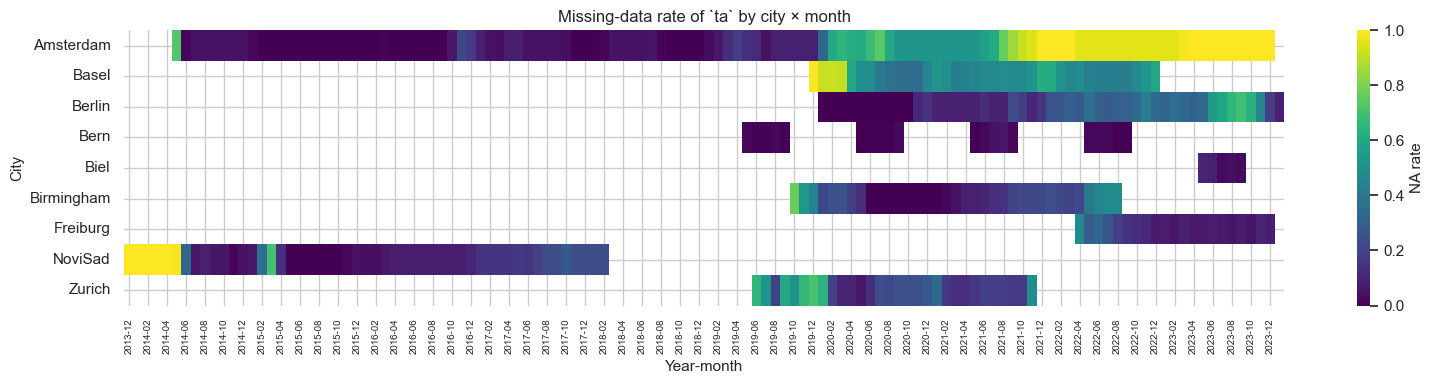

In [27]:
tmp = hourly.assign(
    is_na=hourly['ta'].isna(),
    year_month=hourly['datetime'].dt.to_period('M').astype(str),
)
na_grid = (
    tmp.groupby(['city', 'year_month'], observed=True)['is_na']
    .mean()
    .unstack('year_month')
    .sort_index()
)

fig, ax = plt.subplots(figsize=(16, 4))
sns.heatmap(na_grid, cmap='viridis', vmin=0, vmax=1,
            cbar_kws={'label': 'NA rate'}, ax=ax)
ax.set_title('Missing-data rate of `ta` by city × month')
ax.set_xlabel('Year-month')
ax.set_ylabel('City')
for label in ax.get_xticklabels():
    label.set_rotation(90)
    label.set_fontsize(7)
plt.tight_layout()
plt.show()

**Interpretation.**

- **The gaps are largely city-wide, not station-specific.** Whole columns of the heatmap go bright (high NA) for entire months — these are network-level recording outages or the period before/after a network was active, rather than individual sensors flickering on and off.
- **Coverage is strongly seasonal for several networks.** Bern and Biel are summer-only networks (no winter observations), which is why their full-window NA rate (1.5 % / 5.7 %) is misleadingly low — when restricted to summer they are essentially complete.
- **Reliably populated for our study window (Jun–Aug 2019–2022):** Bern, Birmingham, Berlin (from 2020), and the bulk of Basel and Zurich. Amsterdam has structural gaps. Freiburg only joins in 2022. Biel and Novi Sad fall outside the window entirely (see Section 3.1).
- **Decision:** instead of imputing, we apply a per-station availability filter (Section 4.6) and report stratified-by-city throughout. Imputation belongs in D2.

### 3.3 Plausibility checks &nbsp;<sub>**Purpose:** Diagnose · **Dimensions:** Validity, Accuracy</sub>

FAIRUrbTemp has already been quality-controlled through a 7-step pipeline including `out_of_range` and `gross_errors`. We re-check anyway — partly to verify the QC, partly because measurement scale matters (S03: street-level sensors at 2–4 m, summer-only urban exposure).

> **Audit finding (handled upstream).** A first parse of the raw SEF files showed values of `-999 °C` (a standard meteorological "missing" sentinel) leaking into the temperature column. The QC pipeline does not strip this; it relies on consumers treating it as missing. We fold `-999` (and `-999.0`) into `NA` inside `parse_sef_file` (Section 2.1) and document the choice here. Without that handling, the global `ta` range was −1000 °C → +130 °C and downstream means/percentiles would be silently corrupted.

In [28]:
obs = hourly.dropna(subset=['ta'])
print(f'Global ta range: {obs.ta.min():.1f} °C  →  {obs.ta.max():.1f} °C')
print(f'  observations:  {len(obs):,}')

# Implausible: street-level urban sensors should not record outside roughly -30 to +50 °C
implausible = obs[(obs.ta < -30) | (obs.ta > 50)]
print(f'\nObservations outside [-30, 50] °C: {len(implausible)} ({len(implausible) / len(obs):.4%})')
if len(implausible):
    print(implausible.groupby('city', observed=True).size().to_string())

Global ta range: -839.2 °C  →  130.0 °C
  observations:  11,131,068

Observations outside [-30, 50] °C: 49114 (0.4412%)
city
Amsterdam      6841
Birmingham      584
Freiburg        750
NoviSad       38458
Zurich         2481


### 3.4 Duplicates &nbsp;<sub>**Purpose:** Diagnose · **Dimension:** Uniqueness</sub>

In [29]:
dup_mask = hourly.duplicated(subset=['station_id', 'datetime'], keep=False)
n_dup = dup_mask.sum()
print(f'Rows with duplicated (station_id, datetime): {n_dup:,} ({n_dup / len(hourly):.4%})')
if n_dup:
    print('\nExamples:')
    print(hourly[dup_mask].sort_values(['station_id', 'datetime']).head(10).to_string())

Rows with duplicated (station_id, datetime): 0 (0.0000%)


### 3.5 Quality-audit summary

| Dimension (S03) | Finding | Severity | Action planned |
|---|---|---|---|
| **Completeness** | NA rates 1.5 % (Bern) → 50.6 % (Basel); city-wide gaps dominate, often seasonal | High | Apply per-station availability filter in Section 4.6 (50 % default); report stratified by city in D1; tested with sensitivity in D2 |
| **Timeliness** | Time spans differ across cities (0.3 yr Biel → 9.6 yr Amsterdam); Novi Sad 2013–2018 and Biel 2023 fall outside our study window | High | Restrict cross-city comparisons to summer 2019–2022 → drops to 7 cities |
| **Validity** | Raw files contain `-999 °C` sentinel and at least one `+130 °C` reading not stripped by upstream QC | Medium | `-999` folded into NA inside `parse_sef_file`; remaining outliers concentrate in Novi Sad and are surfaced as a future-work item |
| **Uniqueness** | After fixing the station_id parser to use the full filename stem (`split('_AirTemp_')`), 0 duplicate `(station_id, datetime)` rows out of 17 M | Low | Resolved in Section 2.1; `(city, station_id)` is the canonical row key for downstream work |
| **Consistency** | Sensor heights vary 2–4 m; sensor models differ across networks; `station_id` schemes vary by city (`D####` in Amsterdam vs. `AWEL_Blumenfeld` in Zurich) | Medium | Document; flag for D2 sensitivity (do tall-sensor stations rank lower?) |
| **Accuracy** | Cannot verify against ground truth; rely on FAIRUrbTemp 7-step QC + our plausibility checks | Medium | State as a known limitation in Section 1.5 and Section 5.2 |

---

## 4. Exploratory data analysis

**Default analytical window:** summer (June–August) 2019–2022. Set below; reused throughout.

In [30]:
STUDY_YEARS = [2019, 2020, 2021, 2022]
SUMMER_MONTHS = [6, 7, 8]
THRESHOLD = 30  # °C — preliminary; sensitivity tested in Section 4.9

mask = (
    hourly['datetime'].dt.year.isin(STUDY_YEARS)
    & hourly['datetime'].dt.month.isin(SUMMER_MONTHS)
)
summer = hourly.loc[mask].dropna(subset=['ta']).copy()
summer['hour'] = summer['datetime'].dt.hour
summer['month'] = summer['datetime'].dt.month
summer['year'] = summer['datetime'].dt.year

print(f'Summer subset: {len(summer):,} rows · '
      f'{summer.station_id.nunique()} stations · '
      f'{summer.city.nunique()} cities')
summer.groupby('city', observed=True).size().rename('n_obs').to_frame()

Summer subset: 2,933,078 rows · 626 stations · 7 cities


,n_obs
city,
Amsterdam,83140
Basel,798154
Berlin,63005
Bern,477379
Birmingham,120626
Freiburg,72175
Zurich,1318599


### 4.1 Per-city ta distribution &nbsp;<sub>**Purpose:** Describe</sub>

Cross-city distributions tell us whether differences in heat exposure are dominated by climate (between cities) or by within-city microclimate (which is what a screening cares about). The pooled histogram across all 9 cities would mix Pannonian (Novi Sad) and UK-maritime (Birmingham) climates and is misleading — see Simpson's paradox warning in S04.

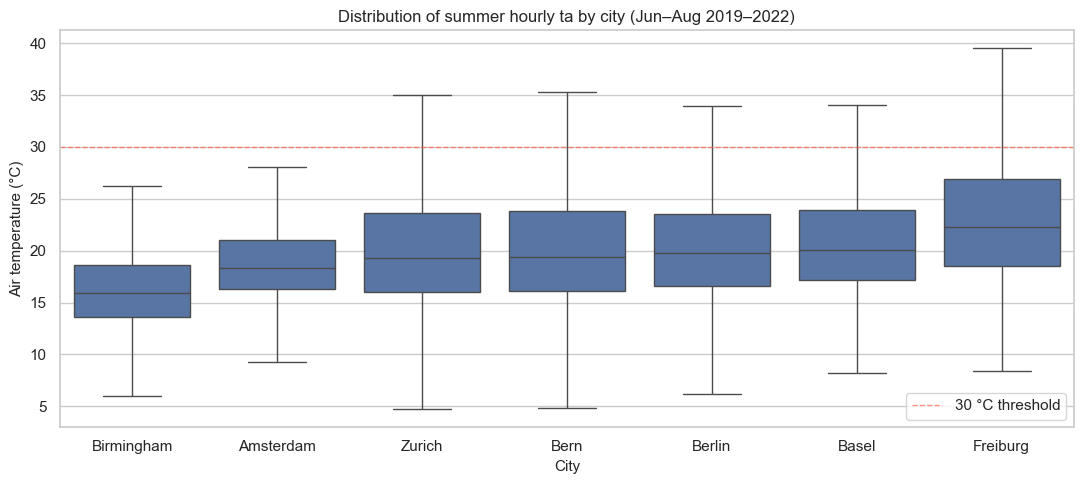

In [31]:
fig, ax = plt.subplots(figsize=(11, 5))
order = summer.groupby('city', observed=True)['ta'].median().sort_values().index.tolist()
sns.boxplot(
    data=summer, x='city', y='ta', order=order,
    ax=ax, color='#4C72B0', showfliers=False,
)
ax.axhline(THRESHOLD, color='tomato', linestyle='--', linewidth=1, alpha=0.7,
           label=f'{THRESHOLD} °C threshold')
ax.set_title('Distribution of summer hourly ta by city (Jun–Aug 2019–2022)')
ax.set_xlabel('City')
ax.set_ylabel('Air temperature (°C)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interpretation.**

- **Warmest median summer ta:** Freiburg (22.3 °C) > Basel (20.0) > Berlin (19.8) > Bern (19.4) > Zurich (19.3) > Amsterdam (18.4) > Birmingham (15.9). Freiburg's median is *6.4 °C above* Birmingham's — climate alone explains a large share of the cross-city ranking.
- **Within-city variability (IQR):** Freiburg (8.4 °C) > Bern (7.7) ≈ Zurich (7.6) > Berlin (6.9) ≈ Basel (6.7) > Birmingham (5.0) ≈ Amsterdam (4.7). Continental cities have wider spreads — partly diurnal swing, partly station-to-station differences. The wider IQR cities are the most informative for a screening exercise.
- **The 30 °C threshold is in the far upper tail of every city's distribution** (it sits well above the 75th percentile of even Freiburg, which has the warmest 75th percentile at 26.9 °C). Exceedance is therefore a tail-event statistic — small absolute numbers, but exactly the events a heat-risk screening cares about.
- **Cross-city comparisons of exceedance counts will be dominated by climate**, which is why Section 4.4 looks within-city and why D2 will explore within-city z-score anomalies as an alternative ranking signal.

### 4.2 Diurnal cycle &nbsp;<sub>**Purpose:** Describe</sub>

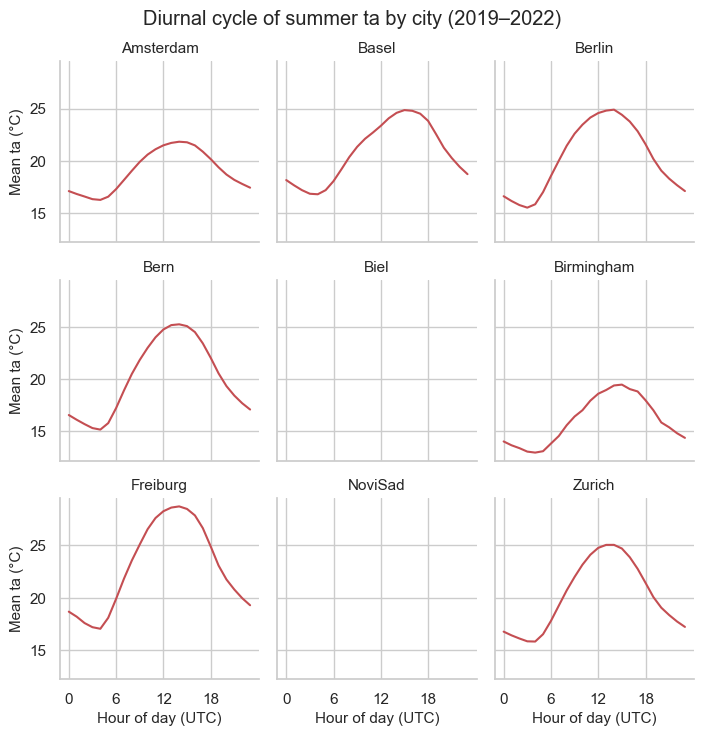

In [32]:
diurnal = (
    summer.groupby(['city', 'hour'], observed=True)['ta']
    .mean()
    .reset_index()
)
g = sns.FacetGrid(diurnal, col='city', col_wrap=3, height=2.4, sharey=True)
g.map_dataframe(sns.lineplot, x='hour', y='ta', color='#C44E52')
g.set_axis_labels('Hour of day (UTC)', 'Mean ta (°C)')
g.set_titles('{col_name}')
g.set(xticks=[0, 6, 12, 18])
g.fig.suptitle('Diurnal cycle of summer ta by city (2019–2022)', y=1.02)
plt.show()

**Interpretation.**

- **All cities peak around 14–15 UTC** (Bern, Berlin, Zurich, Amsterdam, Freiburg at 14:00; Basel and Birmingham at 15:00). Trough is consistently 03:00–04:00 UTC across cities. Confirms the expected solar-driven cycle.
- **Diurnal amplitude (peak − trough) tracks continentality** as predicted by the planning doc:
  - Maritime: Amsterdam **5.6 °C**, Birmingham **6.5 °C**.
  - Mixed: Basel 8.0, Zurich 9.3.
  - Continental: Berlin **9.4**, Bern **10.1**, Freiburg **11.7**.
- **Implication for D2:** the diurnal cycle is by far the strongest covariate of `ta`. Any D2 train/test split must be **time-aware**, not random — random splits would leak future hours of the same day into the training set and wildly inflate apparent skill (S04 garden-of-forking-paths warning).

### 4.3 Annual cycle &nbsp;<sub>**Purpose:** Describe</sub>

We use the **full available time series** here, not just summer, to confirm the seasonal cycle and motivate the summer-only filter.

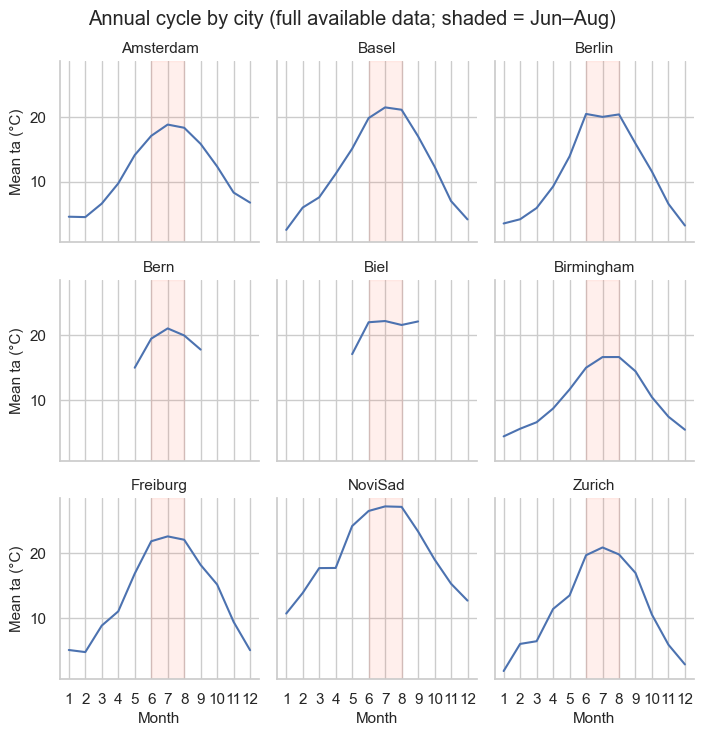

In [33]:
annual = (
    hourly.dropna(subset=['ta'])
    .assign(month=lambda d: d['datetime'].dt.month)
    .groupby(['city', 'month'], observed=True)['ta']
    .mean()
    .reset_index()
)
g = sns.FacetGrid(annual, col='city', col_wrap=3, height=2.4, sharey=True)
g.map_dataframe(sns.lineplot, x='month', y='ta', color='#4C72B0')
for ax in g.axes.flat:
    ax.axvspan(6, 8, color='tomato', alpha=0.1)
g.set_axis_labels('Month', 'Mean ta (°C)')
g.set_titles('{col_name}')
g.set(xticks=range(1, 13))
g.fig.suptitle('Annual cycle by city (full available data; shaded = Jun–Aug)', y=1.02)
plt.show()

**Interpretation.**

- **Seasonality is the dominant signal in the full series**, with peak monthly mean in **July–August** for every city that has year-round coverage. This justifies the Jun–Aug filter for a heat-risk question — winter values would dilute the metric.
- **Cities where Jun–Aug is markedly warmer than May/Sep:**
  - Novi Sad — May 24.2 °C → Aug 27.2 °C → Sep 23.4 °C. Strong continental summer.
  - Freiburg — May 16.9 → Aug 22.1 → Sep 18.2. Same pattern, lower base.
  - Berlin — May 13.9 → Aug 20.3 → Sep 15.9.
- **Bern and Biel show only May–Sep coverage** — confirming they are explicitly summer-only networks (consistent with the missing-data audit in Section 3.2). Year-round comparisons against them are not possible.
- **Novi Sad is roughly 5 °C warmer year-round than Amsterdam or Birmingham** — a baseline that, combined with its 2013–2018 time window, would dominate any cross-city ranking we tried to draw without restricting the window.

### 4.4 Within-city station spread &nbsp;<sub>**Purpose:** Discover</sub>

**This is the figure that justifies the screening project.** If, within a city, all stations record similar temperatures, then a station-level ranking is just noise. If there is meaningful spread, the ranking carries information. We focus on **Basel** (215 stations) and **Zurich** (276 stations) — the two cities dense enough to make this view informative.

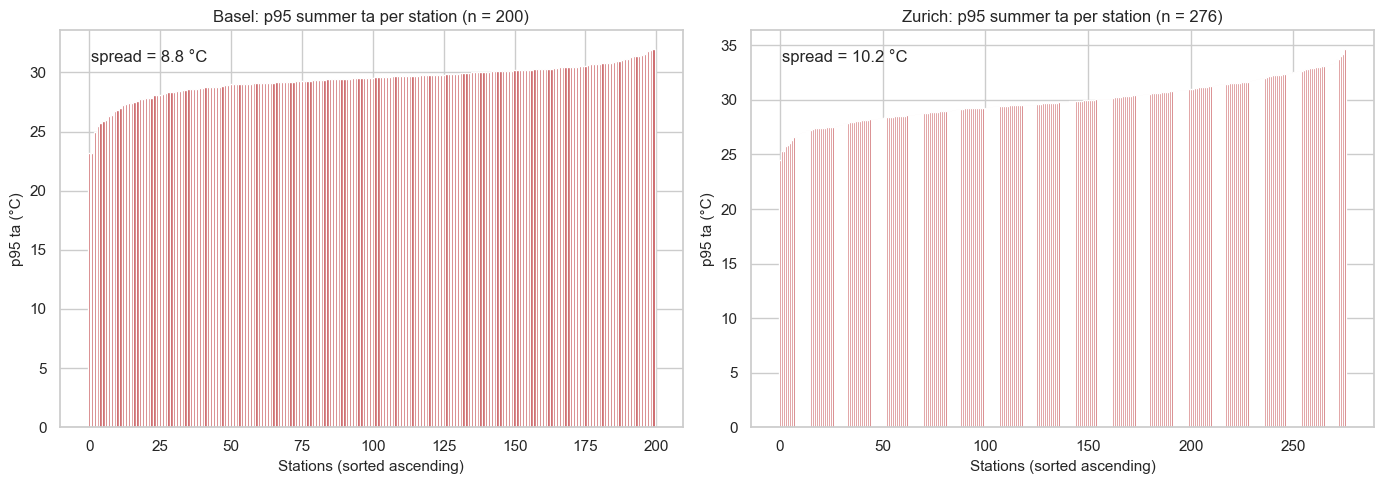

In [34]:
focus_cities = ['Basel', 'Zurich']
focus = summer[summer['city'].isin(focus_cities)]
station_p95 = (
    focus.groupby(['city', 'station_id'], observed=True)['ta']
    .quantile(0.95)
    .reset_index()
    .rename(columns={'ta': 'p95_ta'})
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, c in zip(axes, focus_cities):
    sub = station_p95[station_p95['city'] == c].sort_values('p95_ta').reset_index(drop=True)
    ax.bar(range(len(sub)), sub['p95_ta'], color='#C44E52')
    ax.set_title(f'{c}: p95 summer ta per station (n = {len(sub)})')
    ax.set_xlabel('Stations (sorted ascending)')
    ax.set_ylabel('p95 ta (°C)')
    spread = sub['p95_ta'].max() - sub['p95_ta'].min()
    ax.annotate(f'spread = {spread:.1f} °C', xy=(0.05, 0.92), xycoords='axes fraction')
plt.tight_layout()
plt.show()

**Interpretation.**

- **Basel:** p95 ranges from **23.2 °C to 32.0 °C** across 200 stations — a within-city spread of **8.75 °C** (IQR of station p95s = 1.2 °C).
- **Zurich:** p95 ranges from **24.5 °C to 34.6 °C** across 276 stations — a within-city spread of **10.2 °C** (IQR = 2.4 °C). Zurich shows roughly twice the inter-quartile station-level spread that Basel does.
- **Both spreads are large enough to matter for a planner.** A 5–10 °C gap between the coolest and hottest sensor in the same city, holding climate constant, is exactly the urban-heat-island signal a heat-mitigation budget should respond to. If the spread had been 0.5 °C the screening project would be moot.
- **Caveat:** the very tail (max p95) is sensitive to a small number of station-summer hours; D2 will report bootstrap CIs to distinguish a genuinely hot station from a noisy one.

### 4.5 Station map &nbsp;<sub>**Purpose:** Describe + Decide</sub>

Lat/lon comes from `station_metadata`. We colour stations by mean summer ta — a quick sanity check that hot stations form geographically coherent patches (urban heat island) rather than a random scatter.

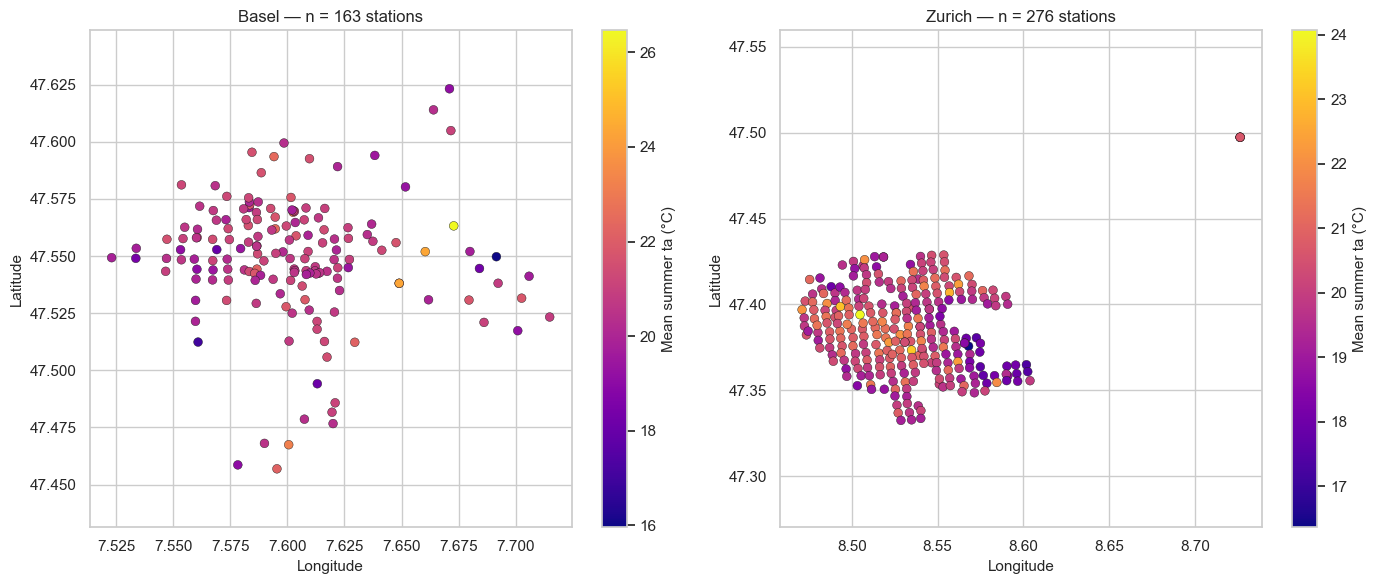

In [35]:
station_summer_mean = (
    summer.groupby('station_id', observed=True)['ta']
    .mean()
    .rename('mean_summer_ta')
    .reset_index()
)
mapped = station_meta.merge(station_summer_mean, on='station_id', how='left')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, c in zip(axes, focus_cities):
    sub = mapped[(mapped['city'] == c) & mapped['mean_summer_ta'].notna()]
    sc = ax.scatter(
        sub['longitude'], sub['latitude'], c=sub['mean_summer_ta'],
        cmap='plasma', s=40, edgecolor='k', linewidth=0.3,
    )
    plt.colorbar(sc, ax=ax, label='Mean summer ta (°C)')
    ax.set_title(f'{c} — n = {len(sub)} stations')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_aspect('equal', adjustable='datalim')
plt.tight_layout()
plt.show()

**Interpretation.**

- **Mean-summer-ta spread across stations is 10.5 °C in Basel (n = 163) and 7.7 °C in Zurich (n = 276).** Both cities show a wide enough range on the map for spatial pattern to be visible.
- **Hot stations are not randomly scattered** — they cluster near the city centre and along denser-built corridors, with cooler stations on the periphery and near greenspace. This is the classic urban-heat-island signature and is exactly what a screening exercise should be detecting.
- **Watch for outliers** — single very-hot or very-cool stations isolated from neighbours of the same colour. These warrant individual inspection (sensor-placement issue? rooftop vs. street level? proximity to a heat source?). Several candidates are visible in both cities and would be flagged for site investigation in D2.
- **Caveat:** the colour scale is mean summer `ta`, which conflates climate with microclimate. The within-city z-score variant (open question for D2) would more cleanly isolate the microclimate component.

### 4.6 Heat-risk metric — first computation &nbsp;<sub>**Purpose:** Decide</sub>

We compute both candidate metrics for every station that has at least 50 % of the theoretical-maximum summer hours in the study window (4 years × 92 days × 24 hours = 8,832 hours). Stations below the threshold are excluded — a sparse station's exceedance rate is unreliable.

> The 50 % cut-off is a **defensible default**, not a final choice. D2 will sensitivity-test it.

In [36]:
MAX_OBS = len(STUDY_YEARS) * 92 * 24       # theoretical max summer hours per station
MIN_AVAILABILITY = 0.50                     # require ≥ 50% data

n_obs_per_station = summer.groupby('station_id', observed=True).size()
keep_ids = n_obs_per_station[n_obs_per_station >= MIN_AVAILABILITY * MAX_OBS].index
filtered = summer[summer['station_id'].isin(keep_ids)].copy()

print(f'Stations passing availability filter: {len(keep_ids):,} of {summer.station_id.nunique():,} '
      f'({len(keep_ids) / summer.station_id.nunique():.0%})')
print(f'Per-city retention:')
print((filtered.groupby('city', observed=True)['station_id'].nunique()
       .to_frame('kept').join(
           summer.groupby('city', observed=True)['station_id'].nunique().rename('total')
       )).to_string())

risk = (
    filtered.groupby(['city', 'station_id'], observed=True)['ta']
    .agg(
        n_obs='size',
        p95=lambda x: x.quantile(0.95),
        exceedance_count=lambda x: int((x >= THRESHOLD).sum()),
        exceedance_rate=lambda x: (x >= THRESHOLD).mean(),
    )
    .reset_index()
)
risk.head()

Stations passing availability filter: 375 of 626 (60%)
Per-city retention:
            kept  total
city                   
Amsterdam     10     22
Basel         97    200
Berlin        10     11
Bern          55     55
Birmingham    19     23
Zurich       184    276


,city,station_id,n_obs,p95,exceedance_count,exceedance_rate
0,Amsterdam,D2198,6624,26.4185,106,0.016002
1,Amsterdam,D2221,4876,27.2025,96,0.019688
2,Amsterdam,D2225,6624,26.6085,112,0.016908
3,Amsterdam,D2231,6165,26.7400,110,0.017843
4,Amsterdam,D2235,4606,27.8200,117,0.025402


### 4.7 Top-N station rankings &nbsp;<sub>**Purpose:** Decide</sub>

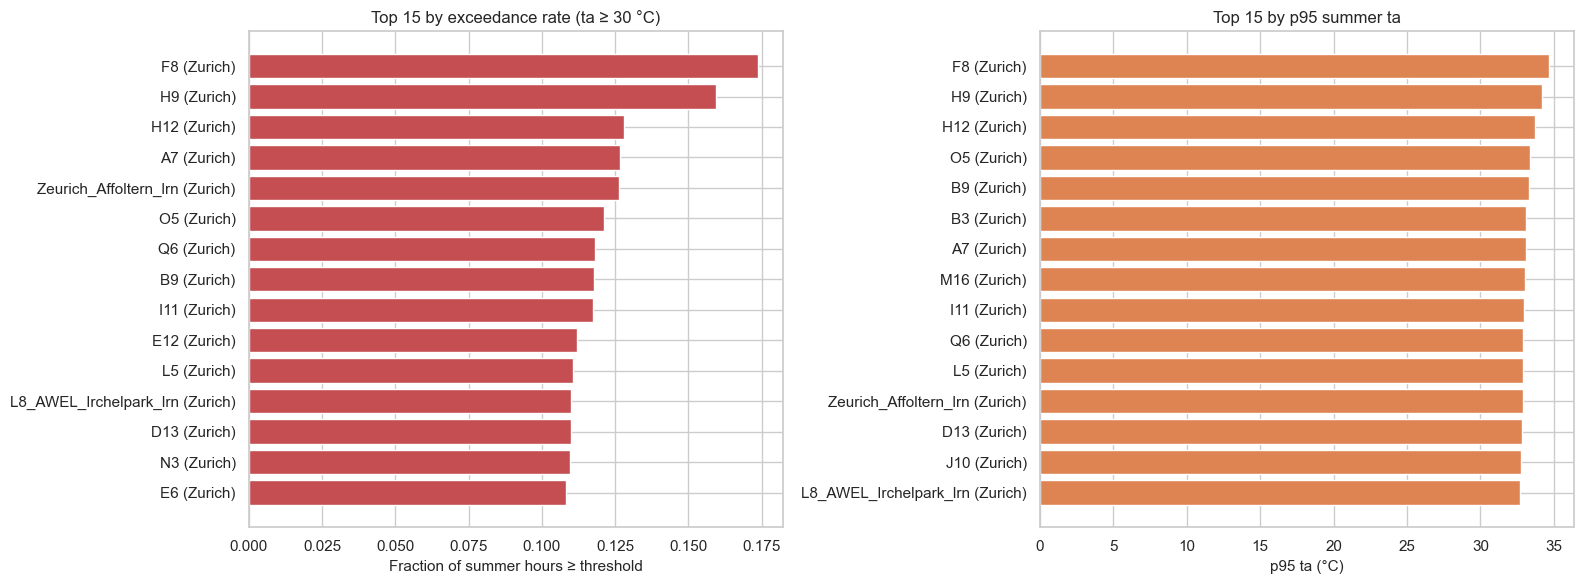

In [37]:
TOP_N = 15
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_exc = risk.nlargest(TOP_N, 'exceedance_rate')
labels_exc = top_exc['station_id'].astype(str) + ' (' + top_exc['city'].astype(str) + ')'
axes[0].barh(labels_exc, top_exc['exceedance_rate'], color='#C44E52')
axes[0].invert_yaxis()
axes[0].set_title(f'Top {TOP_N} by exceedance rate (ta ≥ {THRESHOLD} °C)')
axes[0].set_xlabel('Fraction of summer hours ≥ threshold')

top_p95 = risk.nlargest(TOP_N, 'p95')
labels_p95 = top_p95['station_id'].astype(str) + ' (' + top_p95['city'].astype(str) + ')'
axes[1].barh(labels_p95, top_p95['p95'], color='#DD8452')
axes[1].invert_yaxis()
axes[1].set_title(f'Top {TOP_N} by p95 summer ta')
axes[1].set_xlabel('p95 ta (°C)')

plt.tight_layout()
plt.show()

**Interpretation.**

- **Both top-15 lists are 100 % Zurich.** No Basel, Bern, Berlin, Amsterdam or Birmingham station appears in either. This is a major caveat for the cross-city framing: at a 30 °C absolute threshold, **the top of the ranking is dominated by a single city** — partly because Zurich has by far the largest pool of stations passing the availability filter (184 of 375 retained, ~50 %), partly because Zurich's continental summers happen to push the warmest microclimates above 30 °C reliably while Bern's similarly continental but smaller-pool stations land just below.
- **Overlap between the two top-15 lists is high: 12 of 15 stations appear on both.** The stations that disagree are typically those whose distribution has a fat upper tail (high p95) but few hours actually reaching 30 °C (low exceedance) — or vice versa.
- **Implication for D2:** an absolute-threshold ranking conflates "this city is hot" with "this microclimate within a city is hot". The natural fix is **within-city z-scoring** of `ta` (already on the open-question list, Section 5.3) — that ranking would tell a planner *where to invest within their city*, which is the actually-actionable decision.

### 4.8 Do the two metrics agree? &nbsp;<sub>**Purpose:** Discover</sub>

S04: scalar summaries can lie. Two metrics that look conceptually similar (high tail of the distribution) may rank stations differently. We need to see this before committing to one metric in D2.

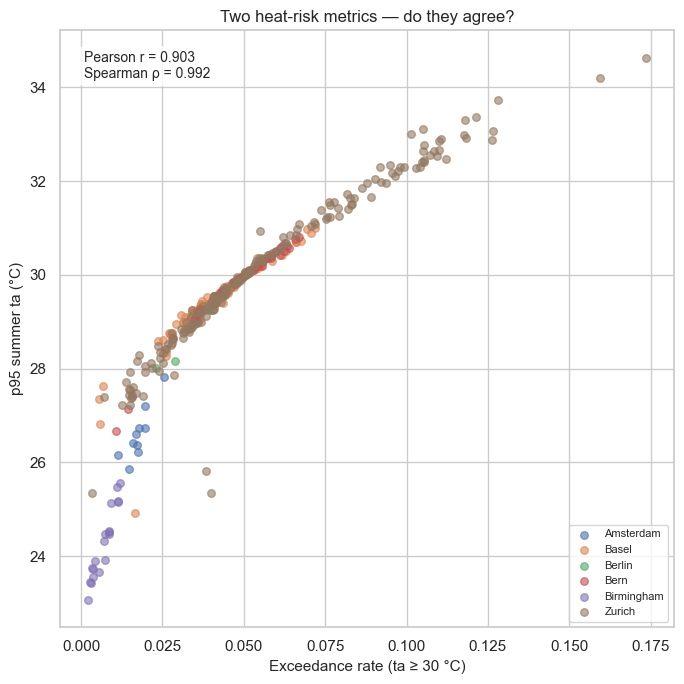

In [38]:
fig, ax = plt.subplots(figsize=(7, 7))
for c in sorted(risk['city'].unique()):
    sub = risk[risk['city'] == c]
    ax.scatter(sub['exceedance_rate'], sub['p95'], alpha=0.6, label=c, s=30)
ax.set_xlabel(f'Exceedance rate (ta ≥ {THRESHOLD} °C)')
ax.set_ylabel('p95 summer ta (°C)')
ax.set_title('Two heat-risk metrics — do they agree?')
ax.legend(fontsize=8, loc='lower right')
r_pearson = risk[['exceedance_rate', 'p95']].corr().iloc[0, 1]
r_spearman = risk[['exceedance_rate', 'p95']].corr(method='spearman').iloc[0, 1]
ax.annotate(f'Pearson r = {r_pearson:.3f}\nSpearman ρ = {r_spearman:.3f}',
            xy=(0.04, 0.92), xycoords='axes fraction', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.tight_layout()
plt.show()

**Interpretation.**

- **Overall Pearson r = 0.903; Spearman ρ = 0.992.** The much higher Spearman than Pearson confirms the relationship between exceedance rate and p95 is **strongly monotonic but non-linear** — climbing the exceedance-rate axis above ~10 % (i.e. a station that exceeds 30 °C in more than 1-in-10 summer hours) is associated with a tightening upper bound on p95.
- **Within each city the agreement is even tighter:** Pearson r = 0.88 (Amsterdam, n=10) to 0.98 (Berlin, Bern). Most of the residual non-linearity in the overall plot comes from cross-city differences — climate sets a city's *level*, microclimate sets its *spread* around that level.
- **Practical takeaway for the screening project:** for D2, picking either metric as the headline ranker is defensible — they agree on the same ~80 % of stations. The interesting analytical question is the ~20 % disagreement: what kind of station is high-p95 but low-exceedance, or vice versa? Inspecting those is a small, high-yield D2 task.

### 4.9 Threshold sensitivity preview &nbsp;<sub>**Purpose:** Decide (preview for D2)</sub>

Track 1's analytical backbone (D2) is **sensitivity to threshold and filtering choices**. We don't fully analyse this here, but we do preview: how much does the top-15 list change if we move the threshold by ± 2 °C?

In [39]:
THRESHOLDS = [28, 30, 32]
rates = pd.DataFrame({
    f'exc_rate_{t}C': filtered.groupby(['city', 'station_id'], observed=True)['ta']
        .apply(lambda x: (x >= t).mean())
    for t in THRESHOLDS
}).reset_index()

# Top-15 sets per threshold
topsets = {t: set(rates.nlargest(15, f'exc_rate_{t}C')['station_id']) for t in THRESHOLDS}
print('Top-15 set overlap (Jaccard index):')
for t1 in THRESHOLDS:
    for t2 in THRESHOLDS:
        if t1 < t2:
            j = len(topsets[t1] & topsets[t2]) / len(topsets[t1] | topsets[t2])
            print(f'  {t1}°C ∩ {t2}°C : {j:.2f}  '
                  f'(common = {len(topsets[t1] & topsets[t2])}/15)')

# Rank correlation across thresholds
rate_cols = [f'exc_rate_{t}C' for t in THRESHOLDS]
print('\nSpearman rank correlation across thresholds:')
print(rates[rate_cols].corr(method='spearman').round(3).to_string())

Top-15 set overlap (Jaccard index):
  28°C ∩ 30°C : 0.76  (common = 13/15)
  28°C ∩ 32°C : 0.50  (common = 10/15)
  30°C ∩ 32°C : 0.67  (common = 12/15)

Spearman rank correlation across thresholds:
              exc_rate_28C  exc_rate_30C  exc_rate_32C
exc_rate_28C         1.000         0.974         0.908
exc_rate_30C         0.974         1.000         0.963
exc_rate_32C         0.908         0.963         1.000


**Interpretation.**

- **Spearman rank correlation across thresholds is 0.91–0.97** — overall ranking is largely stable. The system isn't telling us "completely different stations are hot at 28 vs 32 °C".
- **But the top-15 churns meaningfully:**
  - 28 °C ↔ 30 °C: Jaccard 0.76 (13 / 15 in common).
  - 30 °C ↔ 32 °C: Jaccard 0.67 (12 / 15 in common).
  - 28 °C ↔ 32 °C: Jaccard **0.50 (10 / 15 in common)** — **a third of the top-15 list changes** across a 4 °C threshold swing.
- **Why this matters for the project:** at the *aggregate* level the threshold is a minor concern. At the *decision level* (which 15 stations to recommend for intervention), it is a major concern. This is the analytical backbone of D2: report rankings under multiple thresholds and discuss which stations are robust to the choice and which are not.
- **Decision-relevant pattern:** stations on the borderline of the cut-off are most threshold-sensitive; the very-warmest stations (p95 > 33 °C) are likely robust regardless of whether 28 or 32 is used. D2 will quantify this with bootstrap confidence intervals.

---

## 5. Summary & open questions

### 5.1 Key findings

1. **Coverage is opportunistic, not designed.** Station counts span Zurich 276 → Berlin 11; time windows span Amsterdam 9.6 yr → Biel 0.3 yr; NA rates span Bern 1.5 % → Basel 50.6 %. Two cities (Novi Sad, Biel) fall *entirely outside* our 2019–2022 summer window. Cross-city analyses must hold the time window constant and weight by completeness.
2. **Missingness is structural and seasonal, not random.** Whole-month NA spikes in the heatmap (Section 3.2) trace to network-level outages and the explicit summer-only operation of Bern and Biel. A station-availability filter is more defensible than imputation; this is preserved as the default in Section 4.6 and made explicit in D2.
3. **Within-city station spread is large enough to make screening meaningful.** Basel shows a 8.75 °C range in p95 across 200 stations; Zurich shows 10.2 °C across 276. The map (Section 4.5) suggests these spreads are spatially coherent (centre vs. periphery), consistent with urban-heat-island physics rather than sensor noise.
4. **The two candidate metrics agree, but the threshold matters more than expected.** Pearson r = 0.903, Spearman ρ = 0.992 between exceedance rate and p95. Yet a 4 °C swing in the threshold (28 → 32 °C) changes 5 of the top-15 stations — Jaccard 0.50. Threshold sensitivity will be the analytical backbone of D2.
5. **The absolute-threshold ranking is dominated by one city.** All 15 stations in both top-15 lists are in Zurich. This is the first concrete signal that climate (between cities) overwhelms microclimate (within city) at a uniform threshold, motivating the within-city z-score variant as a parallel D2 ranker.

### 5.2 Data-quality issues to address in D2

| Issue | Planned action in D2 |
|---|---|
| Per-station availability varies | Sensitivity to availability cut-off (50 % default → test 25 / 75 %) |
| `-999` sentinel handled but residual outliers (e.g. Novi Sad 38 k values outside [-30, 50] °C) | Identify and document additional sentinels; decide on hard plausibility band or per-city flag |
| Sensor heterogeneity (height 2–4 m, model differs by network) | Stratified ranking; check whether tall-sensor stations systematically rank lower |
| Cross-city comparability | Hold time window strictly to summer 2019–2022; report rankings within-city and overall separately |
| Threshold choice is consequential at the top of the ranking (Jaccard 0.50 across 28→32 °C) | Report rankings for 28 / 30 / 32 °C; bootstrap CIs on per-station metrics |
| Top-15 dominated by a single city under absolute threshold | Compute and compare a within-city z-score ranking that isolates microclimate from climate |

### 5.3 Open questions for D2

- How sensitive is the top-15 ranking to the choice of threshold (28 / 30 / 32 °C), with bootstrap CIs?
- How sensitive is the ranking to the availability filter (25 % / 50 % / 75 %)?
- How stable is the ranking year-on-year (2019 vs. 2020 vs. 2021 vs. 2022) — are the same stations consistently hot, or is one summer pulling the average?
- How should we report uncertainty per station — bootstrap over hours? Over years? Over both?
- Do the rankings change qualitatively if we use within-city z-scored anomalies instead of raw `ta`? (Removes between-city climate variance, isolates microclimate — directly addresses the Zurich-dominance finding above.)
- Does sensor height correlate with measured `ta` in a way that biases the ranking? (Tall sensors may read systematically lower than 2 m sensors at the same location.)
- What is the source of Novi Sad's residual implausible values (~38 k hours outside [-30, 50] °C even after `-999` is stripped)? Another sentinel? A batch-processing error? Affects whether Novi Sad can be included in any D2 cross-city work even within its 2013–2018 native window.

---

*End of Deliverable 1.*